# 10 · A GEPA search over Jev's words

This notebook reports a search over the words that the frozen method `jev-statement-code` sends
to TypeSafe's Jev model (`jev-1.13.0`): the convention and the eight tag definitions. GEPA
(`gepa.optimize`, version 0.1.4) rewrote them one piece at a time, with `gpt-6-luna` at high
reasoning effort as the reflection model, and the chosen candidate words became a new tagging
method, `jev-statement-code-gepa`. Its question template, `QUESTION`, is the frozen methods'.
The new method is compared with frozen `jev-statement-code` on the held-out fold, the one dev
fold the search never read, and then on the test set, reported once.

**Contents**
1. Setup and checks
2. What GEPA changed
3. The search
4. The held-out fold
5. All of dev, in sample
6. Errors on the held-out fold
7. The test set, reported once
8. Latency and cost per request
9. Takeaways and next steps

**How it was built** ([ADR 0010](../docs/adr/0010-searched-jev-words.md))
- **Three kinds of fold.** GEPA drew its minibatches from the learning folds (dev folds 1-3,
  2,382 problems) and scored every accepted candidate on the selection fold (fold 4, 800
  problems). The held-out fold (fold 0, 806 problems) was never read by the search.
- **The objective is the balanced Brier score.** Per problem, the squared error between Jev's
  probability and the gold 0/1, weighted so that each tag's positives and negatives count
  equally, averaged over the eight tags; GEPA maximised one minus it. Macro F1 through
  cross-fitted thresholds stays the reported metric.
- **The selection rule was fixed before the search.** The chosen candidate has the highest mean
  score on the selection fold among the candidates whose words share no 8-word sequence with a
  dataset problem (statement, notes or solution) that the seed words do not also hold. Ties go
  to the lowest index.
- **Checked before export.** The seed's score on the selection fold, from the search, equals the
  score recomputed from frozen `jev-statement-code` scores, and the chosen words passed the
  dataset-text check. Section 1 recomputes the seed's score, and reads each candidate's outcome of
  the check from the search record (`passed_check`).
- **Fresh answers.** The new method's dev and test answers are new requests with the chosen
  words, in its own committed answers files, not the search's cached answers.
- **In sample.** The words were chosen on dev folds 1-4, so the method is recorded
  `dev_in_sample: true`: a reference, never eligible for the command line's default (ADR 0004,
  ADR 0008). The honest dev comparison is on fold 0, where both methods' thresholds come from
  folds 1-4 and neither method saw a label.
- **Test once.** The test set is reported in section 7, and nothing is chosen from it (ADR 0001).
- **Intervals come from a group bootstrap**: 2,000 resamples of near-duplicate groups, 95%
  percentile intervals, the same resamples for every method, so a paired difference has its own
  interval.

**Running it.** It reads the dataset and frozen files only: the search record
(`assets/methods/jev-statement-code-gepa/tuning/`), the frozen files of
`jev-statement-code-gepa`, `jev-statement`, `jev-statement-code`, `tfidf` and `label_prior`, and
the PNGs of `figures/mlflow/gepa/`. It sends no request and needs no key, no SDK, no GPU, and
neither gepa nor mlflow.

## 1. Setup and checks

Every import and setting first, then the dev and test sets, then each method's frozen files and
the search record, checked before they are used.

In [1]:
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from codeforces_tags.analysis.comparison import method_scores
from codeforces_tags.analysis.plotting import (
    plot_latency,
    plot_method_f1,
    plot_search_progress,
    setup_style,
)
from codeforces_tags.analysis.prompt_search import (
    flipped,
    lineage,
    piece_changes,
    probability_shift,
    refusal_counts,
    search_progress,
)
from codeforces_tags.config import (
    FOCUS_TAGS,
    LATENCY_BUDGET_S,
    MLFLOW_SCREEN_GEPA_FOLDER,
    MLFLOW_SCREEN_GEPA_TAG,
    TUNING_EXPORT_TOLERANCE,
)
from codeforces_tags.conformance import check_frozen_method
from codeforces_tags.data.labels import focus_labels
from codeforces_tags.data.loading import load_dataset
from codeforces_tags.evaluation.predictions import (
    load_per_problem,
    load_predictions,
    load_run_record,
    load_scores,
)
from codeforces_tags.evaluation.report import ALL_PROBLEMS, evaluate
from codeforces_tags.evaluation.timing import latency_summary, load_latency
from codeforces_tags.methods import load_method, method_dir, model_dir
from codeforces_tags.methods.typesafe_jev.objective import (
    balanced_brier,
    macro_balanced_brier,
    problem_scores,
    tag_weights,
)
from codeforces_tags.methods.typesafe_jev.search_record import read_search_record
from codeforces_tags.methods.typesafe_jev.settings import (
    FROZEN_NAMES,
    GEPA_NAME,
    GEPA_SEED_NAME,
    MODEL,
    SEARCH_HELD_OUT_FOLD,
    SEARCH_LEARNING_FOLDS,
    SEARCH_SELECTION_FOLD,
    TUNING_FOLDER,
)
from codeforces_tags.methods.typesafe_jev.words import SEED_WORDS, words_of
from codeforces_tags.splitting import load_split, release_years, select_part

setup_style()
pd.set_option("display.max_colwidth", 110)
TAGS = list(FOCUS_TAGS)
PRIOR, TFIDF = "label_prior", "tfidf"
SEED, GEPA = GEPA_SEED_NAME, GEPA_NAME

In [2]:
problems = load_dataset()
split = load_split()
dev, test = select_part(problems, split, "dev"), select_part(problems, split, "test")
dev_labels, test_labels = focus_labels(dev), focus_labels(test)
folds, groups = dev["fold"], dev["group"]
held_out = (folds == SEARCH_HELD_OUT_FOLD).to_numpy()
learning = dev.index[folds.isin(SEARCH_LEARNING_FOLDS)]
selection = dev.index[folds == SEARCH_SELECTION_FOLD]
print(
    f"dev set: {len(dev):,} problems; learning folds {list(SEARCH_LEARNING_FOLDS)}: "
    f"{len(learning):,}, selection fold {SEARCH_SELECTION_FOLD}: {len(selection):,}, "
    f"held-out fold {SEARCH_HELD_OUT_FOLD}: {held_out.sum():,}; test set: {len(test):,} problems"
)
print(f"positives per tag on the held-out fold: {dev_labels[held_out].sum().to_dict()}")

dev set: 3,988 problems; learning folds [1, 2, 3]: 2,382, selection fold 4: 800, held-out fold 0: 806; test set: 994 problems
positives per tag on the held-out fold: {'math': 226, 'graphs': 87, 'strings': 66, 'number theory': 57, 'trees': 53, 'geometry': 27, 'games': 16, 'probabilities': 15}


In [3]:
records, dev_by_method, test_by_method, dev_probabilities = {}, {}, {}, {}
for name in [PRIOR, TFIDF, *FROZEN_NAMES, GEPA]:
    check_frozen_method(name, split=split)
    records[name] = load_run_record(method_dir(name))
    assert records[name].method == name
    frozen = load_predictions(method_dir(name))
    dev_by_method[name] = frozen.loc["dev", TAGS]
    test_by_method[name] = frozen.loc["test", TAGS]
    assert dev_by_method[name].index.equals(dev.index), name
    assert test_by_method[name].index.equals(test.index), name
for name in [*FROZEN_NAMES, GEPA]:
    dev_probabilities[name] = load_scores(method_dir(name)).loc["dev", TAGS]
    assert dev_probabilities[name].index.equals(dev.index), name
    assert records[name].method_entries["served_models"] == [MODEL], name
for name in [PRIOR, *FROZEN_NAMES]:
    assert records[name].method_entries["dev_in_sample"] is False, name
assert records[GEPA].method_entries["dev_in_sample"] is True
search_entries = records[GEPA].method_entries["search"]
assert search_entries["held_out_fold"] == SEARCH_HELD_OUT_FOLD
assert search_entries["selection_fold"] == SEARCH_SELECTION_FOLD
assert search_entries["learning_folds"] == list(SEARCH_LEARNING_FOLDS)
print(f"frozen and checked: {list(dev_by_method)}")

frozen and checked: ['label_prior', 'tfidf', 'jev-statement', 'jev-statement-code', 'jev-statement-code-gepa']


The search record: the parameters of the search and the chosen words (`params.json`), one row
per candidate scored on the selection fold (`candidates.csv`), one row per iteration
(`history.csv`) and the words of every candidate that passed the dataset-text check. The cell
checks the selection rule, the chosen words against the method folder, and the seed check: the
seed's mean score on the selection fold, recomputed here from the frozen scores of
`jev-statement-code` with the weights of the learning folds.

In [4]:
record = read_search_record(method_dir(GEPA) / TUNING_FOLDER)
params, candidates, history = record.params, record.candidates, record.history
chosen = params["chosen"]
chosen_words = record.words[chosen]
assert chosen_words.sha256() == params["words_sha256"] == words_of(GEPA).sha256()
assert load_method(model_dir(GEPA)).words.sha256() == chosen_words.sha256()
assert candidates["passed_check"].dtype == bool
passing = candidates.loc[candidates["passed_check"], "selection_mean"]
assert passing[passing == passing.max()].index.min() == chosen, "the selection rule"
assert np.isclose(
    candidates.at[chosen, "selection_mean"],
    params["chosen_selection_mean"],
    rtol=0,
    atol=TUNING_EXPORT_TOLERANCE,
)
weights = tag_weights(dev_labels.loc[learning])
prevalence = dev_labels.loc[learning].mean()
assert np.allclose(prevalence, pd.Series(params["prevalence"])[TAGS], rtol=0, atol=1e-12)
seed_scores = problem_scores(
    dev_probabilities[SEED].loc[selection], dev_labels.loc[selection], weights
)
assert abs(seed_scores.mean() - params["seed_selection_mean"]) <= TUNING_EXPORT_TOLERANCE
print(
    f"{len(candidates)} candidates scored on the selection fold, "
    f"{int(candidates['passed_check'].sum())} passed the dataset-text check; chosen: "
    f"candidate {chosen}, mean score {params['chosen_selection_mean']:.4f} against the seed's "
    f"{params['seed_selection_mean']:.4f} (recomputed: {seed_scores.mean():.4f})"
)
recorded_cost = {part: round(usd, 4) for part, usd in params["cost_usd"].items()}
print(
    f"search: gepa {params['gepa_version']}, stopped by {params['stop_reason']} after "
    f"{params['iterations']} iterations, cost in USD {recorded_cost}, caps {params['caps']}"
)
weights.round(3)

71 candidates scored on the selection fold, 71 passed the dataset-text check; chosen: candidate 69, mean score 0.9135 against the seed's 0.9091 (recomputed: 0.9091)
search: gepa 0.1.4, stopped by iterations after 200 iterations, cost in USD {'jev': 9.5518, 'luna': 0.3959, 'total': 9.9477}, caps {'max_cost_usd': 15.0, 'max_iterations': 200}


,0,1
tag,,
math,0.699,1.759
graphs,0.562,4.563
strings,0.547,5.867
number theory,0.537,7.175
trees,0.535,7.635
geometry,0.517,14.888
games,0.511,23.353
probabilities,0.510,26.467


## 2. What GEPA changed

Each piece of the seed words against the chosen words: its length (the convention's characters,
or a tag's criteria as compact JSON, which the length cap of 1.5 times the seed's bounds),
whether it changed, how many words were removed or added, then the word-level diff of each piece
that changed (`[-removed-]`, `{+added+}`).

In [5]:
changes = piece_changes(SEED_WORDS, chosen_words)
changes["chars_change"] = changes["chosen_chars"] - changes["seed_chars"]
display(changes.drop(columns="diff"))
for piece in changes.index[changes["changed"]]:
    print(f"\n{piece}, {changes.at[piece, 'changed_words']} words removed or added:")
    print(textwrap.fill(changes.at[piece, "diff"], width=100))

,seed_chars,chosen_chars,length_cap,changed,changed_words,chars_change
piece,,,,,,
convention,150,150,225,False,0,0
math,818,1190,1227,True,149,372
graphs,687,687,1030,False,0,0
strings,650,650,975,False,0,0
number theory,594,594,891,False,0,0
trees,658,658,987,False,0,0
geometry,522,522,783,False,0,0
games,647,647,970,False,0,0
probabilities,639,857,958,True,134,218



math, 149 words removed or added:
{ "true": { "definition": "The intended solution [-needs-]{+uses+} a {+nontrivial+} mathematical
[-idea beyond routine arithmetic. Math-]{+deduction or model as a central idea, even if implemented
with a standard algorithm. A topic that sounds mathematical+} is [-the broadest tag and often comes
with number theory, geometry, probabilities or games.",-]{+not enough by itself.",+} "includes": [
"deriving a formula or closed form for the answer", "parity, invariants or bounds proved [-with
arithmetic",-]{+arithmetically",+} "combinatorial counting, binomial coefficients, inclusion-
exclusion", "sums, sequences [-and-]{+or+} inequalities that reduce [-the-] search", [-"modular
arithmetic used to compute a large count"-]{+"geometric distance and extremal-coordinate arguments",
"digit recurrences or modular cycles with useful structure", "conservation equations characterizing
feasibility", "nontrivial probability derivations"+} ] }, "false": { "definition":

What the new words cost per request: each method's mean input tokens and cost per request, by
part, from the recorded calls of its answers files (`per_problem.csv`), and the new method's
failed answers. Jev bills input tokens only (`config.LLM_PRICES`). Last, what a request of
`jev-statement`, which leaves the solution out, reads against one of `jev-statement-code`, over
every dev and test problem (section 9's next steps).

In [6]:
calls = {name: load_per_problem(method_dir(name)) for name in (SEED, GEPA)}
request_size = pd.concat(
    {
        name: frame.groupby(level="part", sort=False)[["input_tokens", "total_cost_usd"]].mean()
        for name, frame in calls.items()
    },
    axis="columns",
)
input_change = request_size[(GEPA, "input_tokens")] - request_size[(SEED, "input_tokens")]
failed = (calls[GEPA]["status"] != "completed").groupby(level="part", sort=False).sum()
print(f"input tokens per request, {GEPA} minus {SEED}: {input_change.round(1).to_dict()}")
print(f"failed answers of {GEPA}: {failed.to_dict()}")
statement_only = load_per_problem(method_dir("jev-statement"))["input_tokens"].mean()
with_solution = calls[SEED]["input_tokens"].mean()
print(
    f"input tokens per request over every problem: jev-statement {statement_only:,.1f}, "
    f"{SEED} {with_solution:,.1f}, {1 - statement_only / with_solution:.1%} fewer"
)
request_size.round(6)

input tokens per request, jev-statement-code-gepa minus jev-statement-code: {'dev': 112.0, 'test': 112.0}
failed answers of jev-statement-code-gepa: {'dev': 0, 'test': 0}
input tokens per request over every problem: jev-statement 2,770.4, jev-statement-code 3,189.9, 13.1% fewer


jev-statement-code                jev-statement-code-gepa               
           input_tokens total_cost_usd            input_tokens total_cost_usd
part                                                                         
dev         3197.757021       0.000134             3309.757021       0.000139
test        3158.320926       0.000133             3270.320926       0.000137

**The chosen words rewrote two pieces, math and probabilities, and kept the convention and the six other tag definitions of the seed word for word.**

- Math grew from 818 to 1,190 characters (+372, under its cap of 1,227), with 149 words removed or added; probabilities grew from 639 to 857 characters (+218, under its cap of 958), with 134.
- Math: the yes now asks for a nontrivial mathematical deduction or model as a central idea of the intended solution, even inside a standard algorithm, adds geometric, digit, modular-cycle, conservation and probability arguments to what it includes, and drops the line that math is the broadest tag and often comes with number theory, geometry, probabilities or games; the no adds that a math-themed statement or quantity alone, distances computed directly, a lone gcd or residue test and expectations handled by routine dynamic programming do not make the tag.
- Probabilities: the yes moves from an answer that is a probability or an expectation to a solution that computes one or uses probabilistic reasoning as a core idea, drops the random choices a statement describes (coins, dice, uniform picks) and turns randomized algorithms that rely on chance from a no into a yes; the no now names counting game outcomes, randomized hashing and incidental random choices or tie-breaking.
- Every request carries all eight definitions, so the longer words add 112.0 input tokens per request on both parts: from 3,197.8 to 3,309.8 on dev and from 3,158.3 to 3,270.3 on test. The mean cost per request goes from $0.000134 to $0.000139 on dev and from $0.000133 to $0.000137 on test.
- No answer of `jev-statement-code-gepa` failed, on dev or on test.

Both rewrites tie the yes to a core idea of the intended solution rather than to the topic of the statement, at 112.0 more input tokens per request.

## 3. The search

Iteration by iteration: the best mean score on the selection fold so far among the candidates
that passed the dataset-text check (the selection rule's choice at that point), then the
cumulative cost of Jev, of the reflection model and of both, from the history's per-iteration
costs. A marker shows an iteration whose child GEPA accepted: the child beat its parent on the
minibatch and was then scored on the selection fold, which need not raise the best score so far.
A marker is an accepted child, not an improvement.

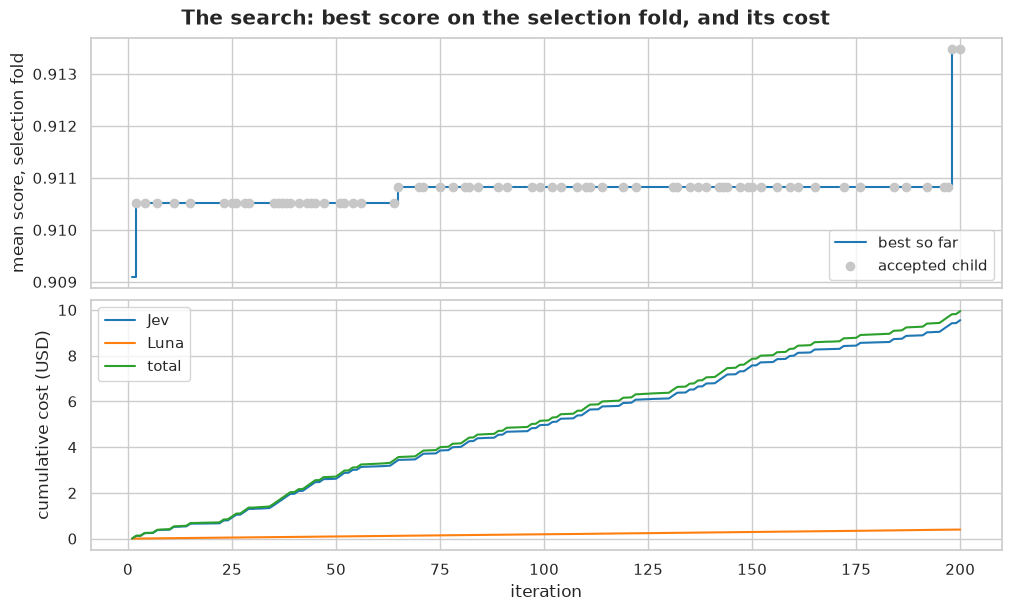

200 iterations, 70 children accepted; cost from the history: {'jev_cost_usd': 9.5518, 'luna_cost_usd': 0.3959, 'total_cost_usd': 9.9477}; recorded by export: {'jev': 9.5518, 'luna': 0.3959, 'total': 9.9477}


In [7]:
progress = search_progress(history, candidates)
assert np.isclose(
    progress["best_selection_mean"].iloc[-1],
    params["chosen_selection_mean"],
    rtol=0,
    atol=TUNING_EXPORT_TOLERANCE,
)
figure = plot_search_progress(progress)
figure.suptitle("The search: best score on the selection fold, and its cost", fontweight="bold")
plt.show()
spent = progress.iloc[-1][["jev_cost_usd", "luna_cost_usd", "total_cost_usd"]]
print(
    f"{len(progress)} iterations, {int(progress['accepted'].sum())} children accepted; "
    f"cost from the history: {spent.round(4).to_dict()}; recorded by export: {recorded_cost}"
)

The ten best candidates on the selection fold, with their per-tag balanced Brier score (lower
is better), then the candidates that failed the dataset-text check, each with the number of
8-word sequences its words shared with a dataset problem. Neither those sequences nor the
failing candidates' words are in `tuning/`: the sequences are dataset text.

In [8]:
shown = candidates.drop(columns=["words_sha256", "copied_sequences"])
display(shown.sort_values("selection_mean", ascending=False).head(10).round(4))
failing = ["iteration", "piece", "selection_mean", "copied_sequences"]
candidates.loc[~candidates["passed_check"], failing]

,parents,iteration,piece,selection_mean,brier_math,brier_graphs,brier_strings,brier_number_theory,brier_trees,brier_geometry,brier_games,brier_probabilities,passed_check
index,,,,,,,,,,,,,
69,1,198,probabilities,0.9135,0.1845,0.0742,0.0875,0.0628,0.0788,0.0829,0.0305,0.1047,True
26,17,65,math,0.9108,0.1786,0.0744,0.0867,0.0842,0.0801,0.0829,0.0311,0.1096,True
1,0,2,math,0.9105,0.1842,0.0747,0.0869,0.0632,0.0794,0.0824,0.0306,0.1299,True
47,1,132,games,0.9104,0.1850,0.0747,0.0878,0.0635,0.0789,0.0817,0.0307,0.1306,True
17,10,43,probabilities,0.9103,0.1847,0.0745,0.0864,0.0833,0.0810,0.0834,0.0311,0.1073,True
16,1,41,trees,0.9098,0.1846,0.0747,0.0868,0.0629,0.0838,0.0829,0.0311,0.1306,True
56,47,150,probabilities,0.9097,0.1854,0.0746,0.0865,0.0622,0.0801,0.0833,0.0319,0.1348,True
38,27,102,games,0.9096,0.1983,0.0741,0.0864,0.0626,0.0765,0.0822,0.0292,0.1300,True
33,31,84,probabilities,0.9094,0.1981,0.0739,0.0873,0.0637,0.0797,0.0825,0.0294,0.1259,True


,iteration,piece,selection_mean,copied_sequences
index,,,,


The chosen candidate's lineage, from the seed: at which iteration each ancestor changed which
piece, and what it gained on the selection fold over its parent. Then the proposals the search
refused, by reason (a refused piece keeps its parent's text, so its child cannot be accepted),
and how often each piece's child was accepted.

In [9]:
display(lineage(candidates, chosen).round(4))
display(refusal_counts(history).to_frame())
acceptance = progress.join(history["piece"]).groupby("piece", sort=False)["accepted"]
pd.DataFrame({"iterations": acceptance.size(), "accepted": acceptance.sum()})

,iteration,piece,selection_mean,gain
index,,,,
0,0,,0.9091,NaN
1,2,math,0.9105,0.0014
69,198,probabilities,0.9135,0.0030


,iterations
reason,
failed_answer,0
invalid_json,0
empty_field,0
too_long,104
copied_text,0


,iterations,accepted
piece,,
convention,22,7
math,25,11
graphs,30,8
strings,22,4
number theory,17,6
trees,17,12
geometry,23,2
games,20,13
probabilities,24,7


**GEPA ran its 200 iterations to the cap, and the chosen words are two steps from the seed: math at iteration 2 and probabilities at iteration 198.**

- The search stopped on its iteration cap (stop reason `iterations`) after 200 iterations, and GEPA accepted 70 children: convention 7 of 22 iterations, math 11 of 25, graphs 8 of 30, strings 4 of 22, number theory 6 of 17, trees 12 of 17, geometry 2 of 23, games 13 of 20 and probabilities 7 of 24.
- 71 candidates were scored on the selection fold, the seed and the 70 accepted children, and all 71 passed the dataset-text check, so the selection rule chose among all of them.
- The chosen candidate, 69, scores 0.9135 on the selection fold against the seed's 0.9091 (recomputed here from the frozen scores of `jev-statement-code` at the same value), a gain of 0.0044.
- Its lineage has two steps from the seed: candidate 1 rewrote math at iteration 2 (+0.0014), and its child, candidate 69, rewrote probabilities at iteration 198 (+0.0030). In between, the best score so far moved once, to 0.9108, with candidate 26, a math rewrite at iteration 65; every other accepted child beat its parent on its minibatch but scored below the best candidate on the selection fold.
- 104 of the 200 proposals were refused, all as too long (`too_long`): the reflection model's piece went past its length cap. None was refused for an invalid JSON answer, an empty field, a failed answer or copied text. The chosen math (1,190 of 1,227 characters) and probabilities (857 of 958) both sit near their caps (section 2).
- The search cost $9.9477 as `export` recorded it, $9.5518 of Jev and $0.3959 of the reflection model, under the $15 cap; the per-iteration costs of the history add up to the same.

The gain on the selection fold is small, 0.0044 of mean score, and its larger step came at iteration 198 of 200; section 4 asks whether it holds on the fold the search never read.

### The search in MLflow

The search was logged live to the MLflow experiment `jev-gepa` while it ran, and
`python -m codeforces_tags.methods.typesafe_jev log-search` replays the committed record
(`tuning/`) into an empty store with no request. The screenshots below come from such a rebuilt
local store (`notebooks/README.md`, Figures), taken by `notebooks/figures/mlflow_ui.py --set
gepa`: the parent run `search-jev-statement-code-gepa` with its metrics by iteration, one nested
run per candidate scored on the selection fold, and one registered prompt per piece,
`jev-gepa-<piece>`, whose version 1 is the seed's text and each later version a candidate's.
They show dev folds 1-4 only: the search never read fold 0 or the test set.

In [10]:
most_changed = changes.drop(index="convention")["changed_words"].idxmax()
assert most_changed == MLFLOW_SCREEN_GEPA_TAG, "the screenshots compare another tag's versions"
assert changes.at[MLFLOW_SCREEN_GEPA_TAG, "changed"], "the compared versions are the same words"
print(
    f"The prompt comparison shows jev-gepa-{MLFLOW_SCREEN_GEPA_TAG.replace(' ', '-')}, the tag "
    f"whose words changed most ({changes.at[MLFLOW_SCREEN_GEPA_TAG, 'changed_words']} words); "
    f"the convention changed: {bool(changes.at['convention', 'changed'])}."
)
convention_png = MLFLOW_SCREEN_GEPA_FOLDER / "04_gepa_convention_compare.png"
assert convention_png.exists() == bool(changes.at["convention", "changed"])

The prompt comparison shows jev-gepa-math, the tag whose words changed most (149 words); the convention changed: False.


**1. The parent run's charts.** `selection_best_score`, the best mean score on the selection
fold so far, and the cumulative costs `cost_usd_jev`, `cost_usd_luna` and `cost_usd_total`, with
the iteration as the step; beside them `accepted`, the minibatch sums of the parent and the
child, and each tag's balanced Brier score of the best candidate so far (`selection_brier.<tag>`).
The MLflow metric `selection_best_score` counts every candidate, including any that the
dataset-text check refused afterwards: the live log could not know the check, which `export`
runs once the search has stopped, and the replay logs the same. The chart of section 3
(`search_progress`) counts the passing candidates only, as the selection rule does, so the two
curves would differ wherever a refused candidate held the best score. Here every candidate
passed (section 1), so they are the same curve.

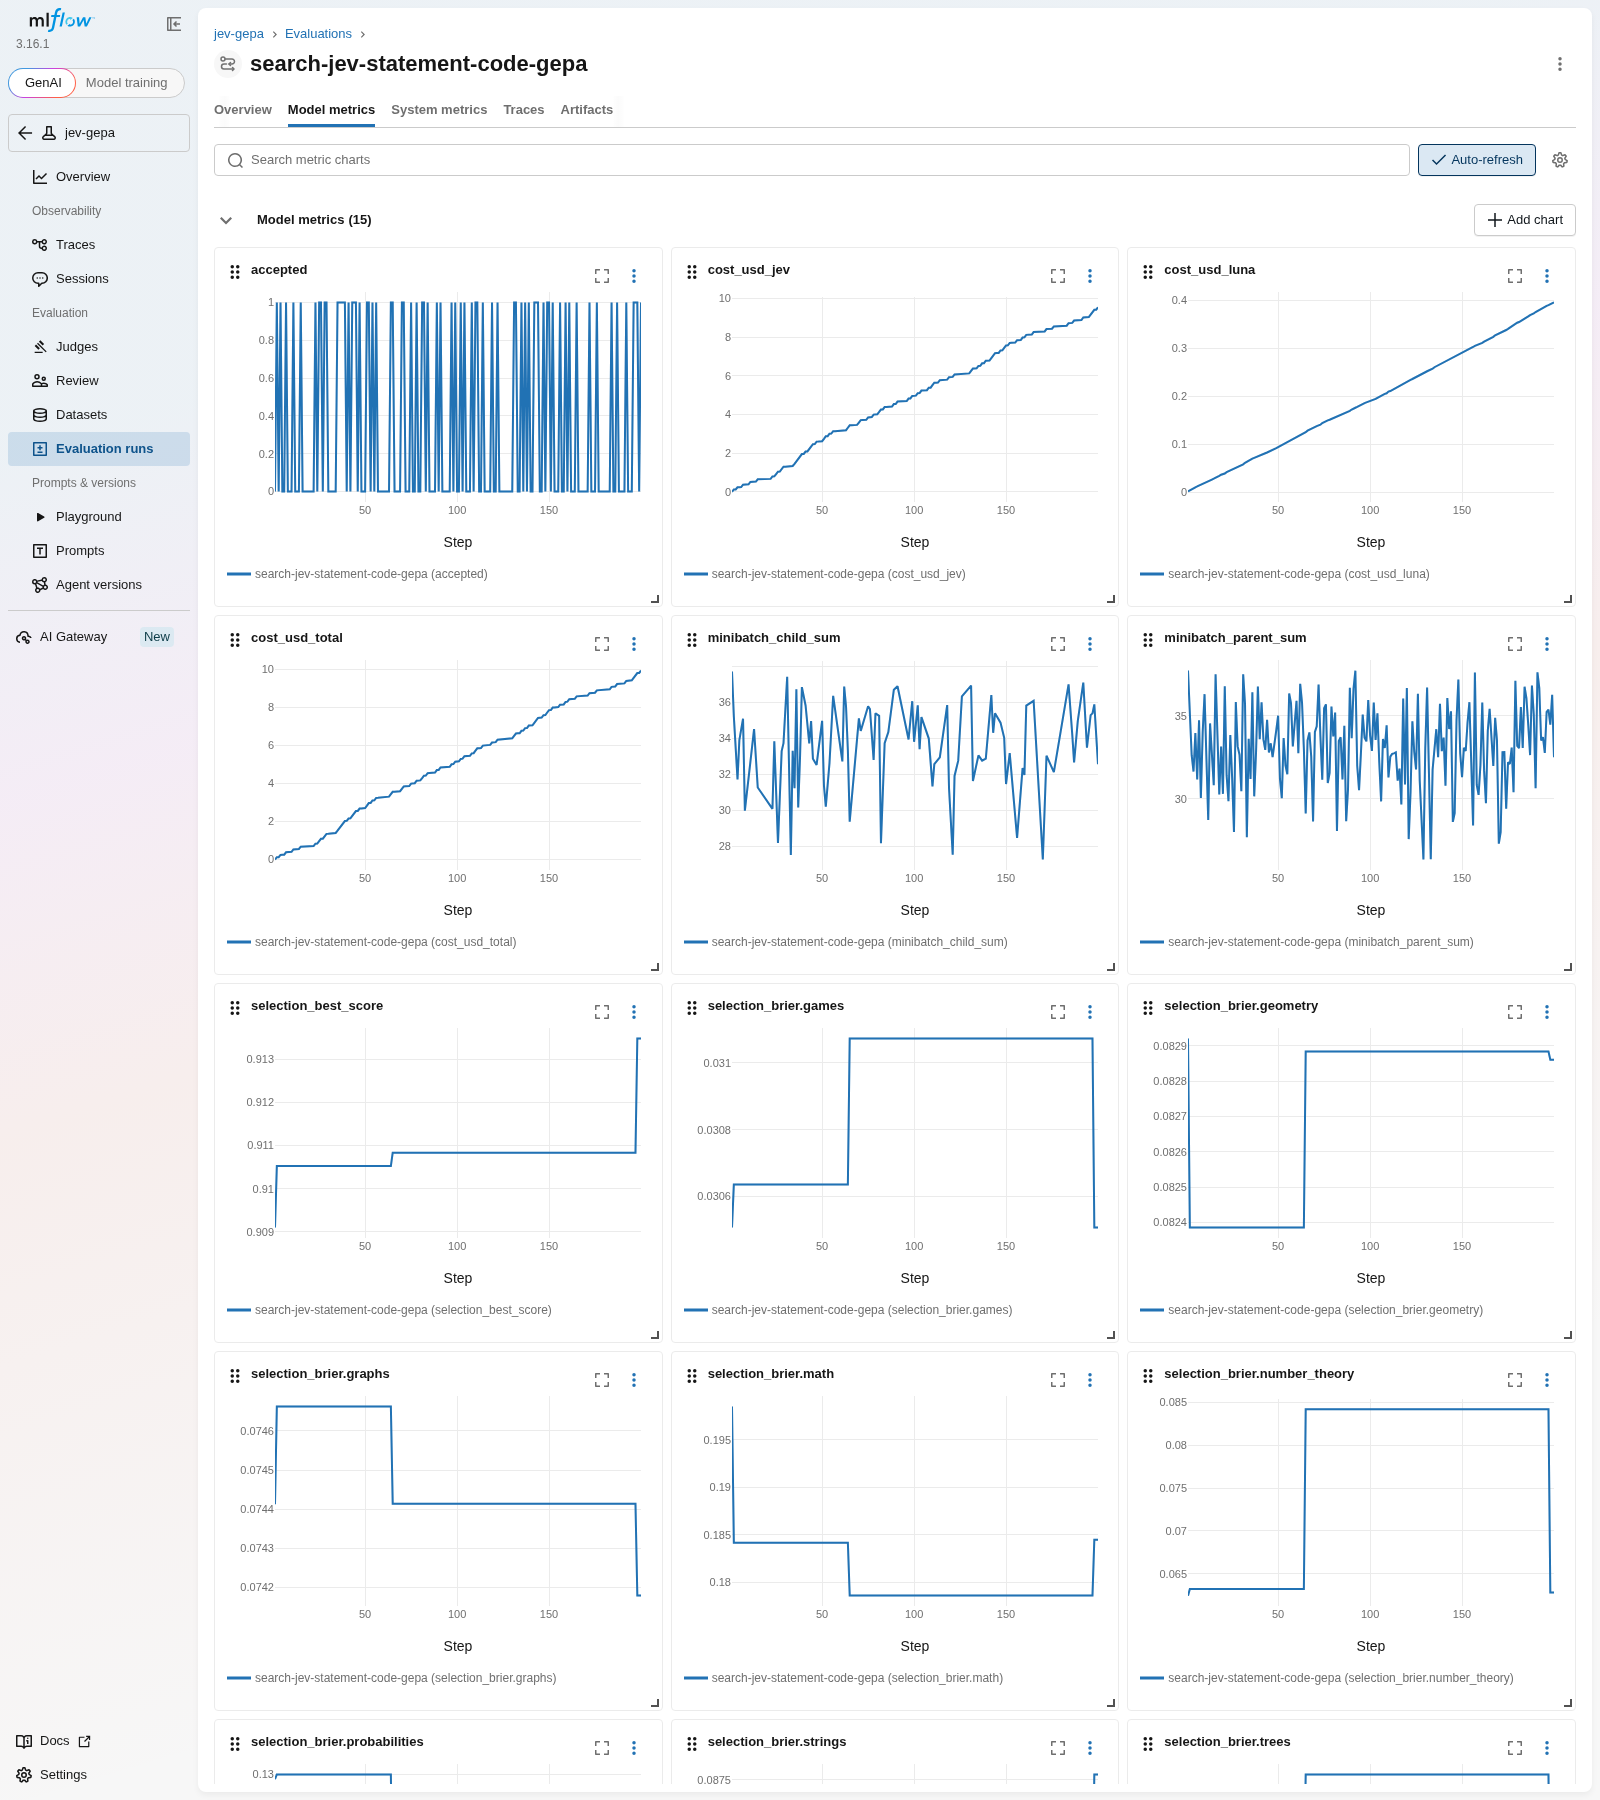

In [11]:
Image(filename=MLFLOW_SCREEN_GEPA_FOLDER / "01_gepa_search_chart.png", width=960)

**2. The candidate runs.** One nested run per candidate scored on the selection fold, sorted by
its mean score, with the piece it changed, its iteration and whether its words passed the
dataset-text check.

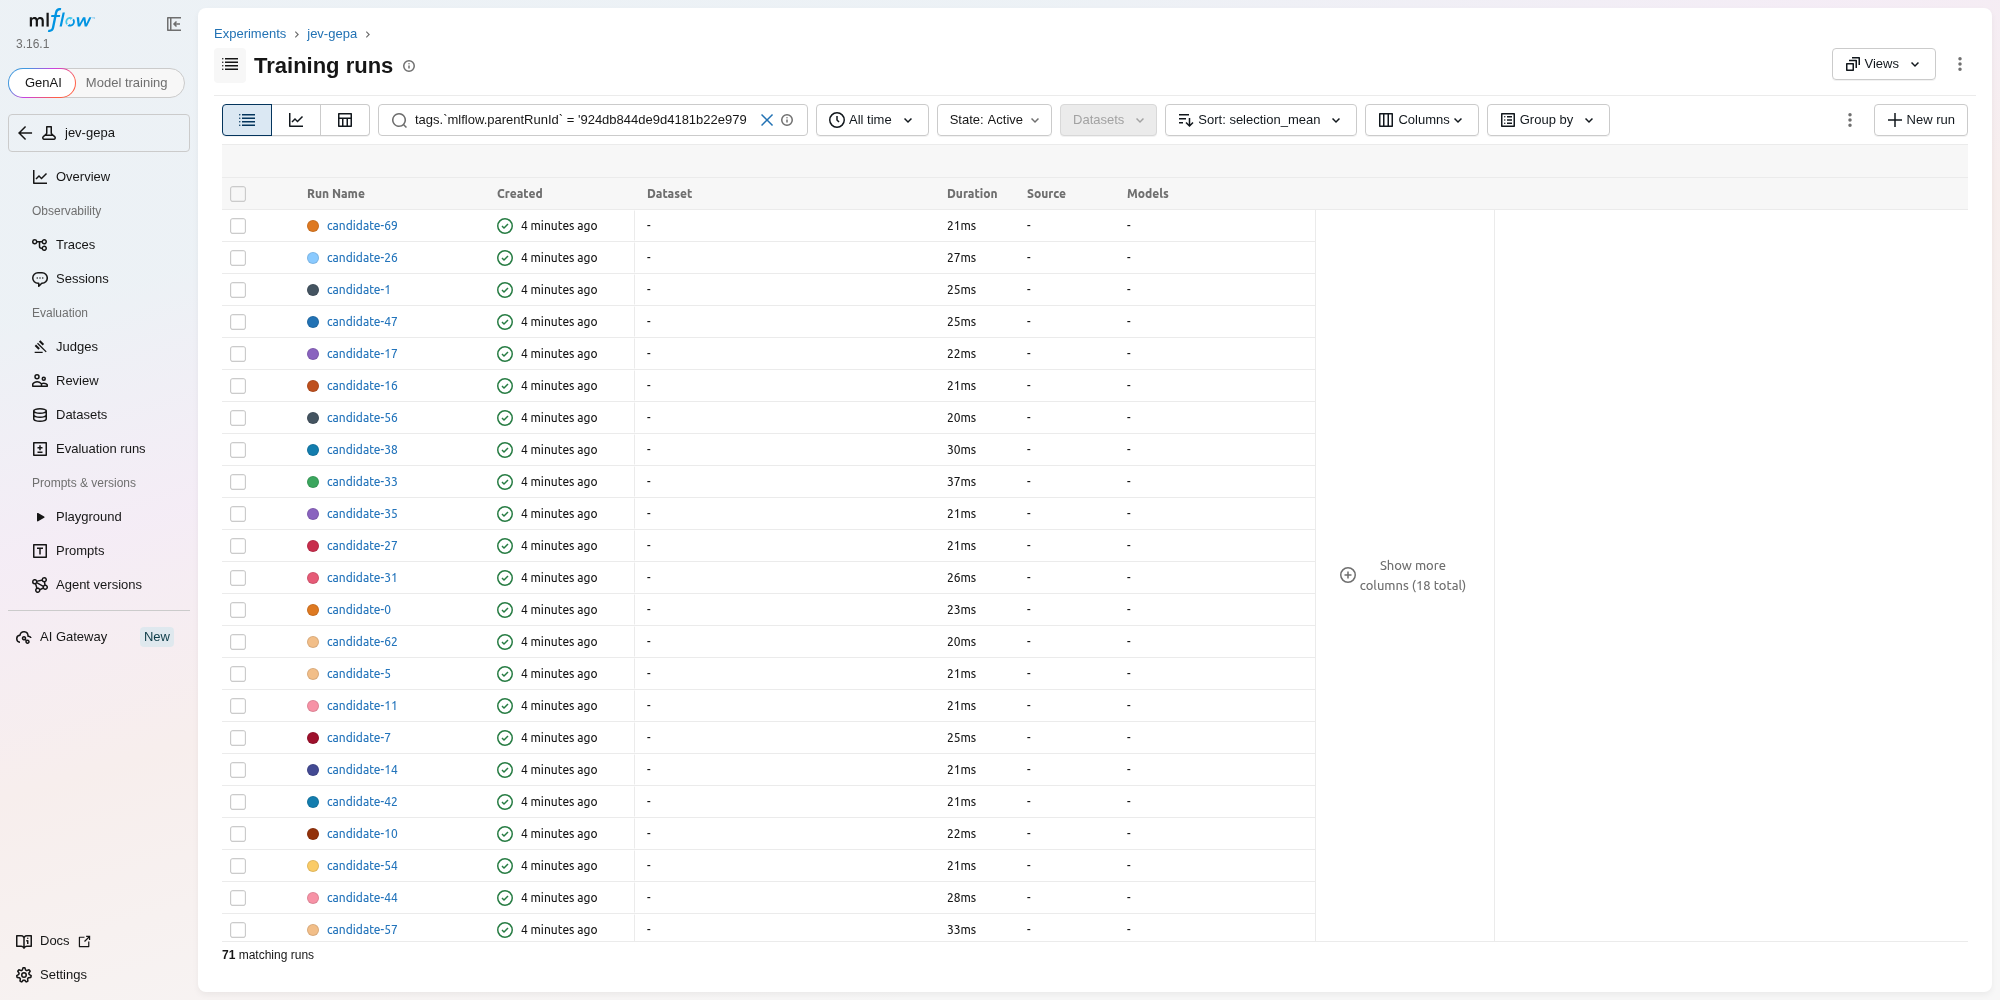

In [12]:
Image(filename=MLFLOW_SCREEN_GEPA_FOLDER / "02_gepa_candidates.png", width=960)

**3. One piece, before and after.** The prompt of the tag whose words changed most, its version
1 (the seed's criteria) against the chosen candidate's version, in MLflow's prompt comparison.

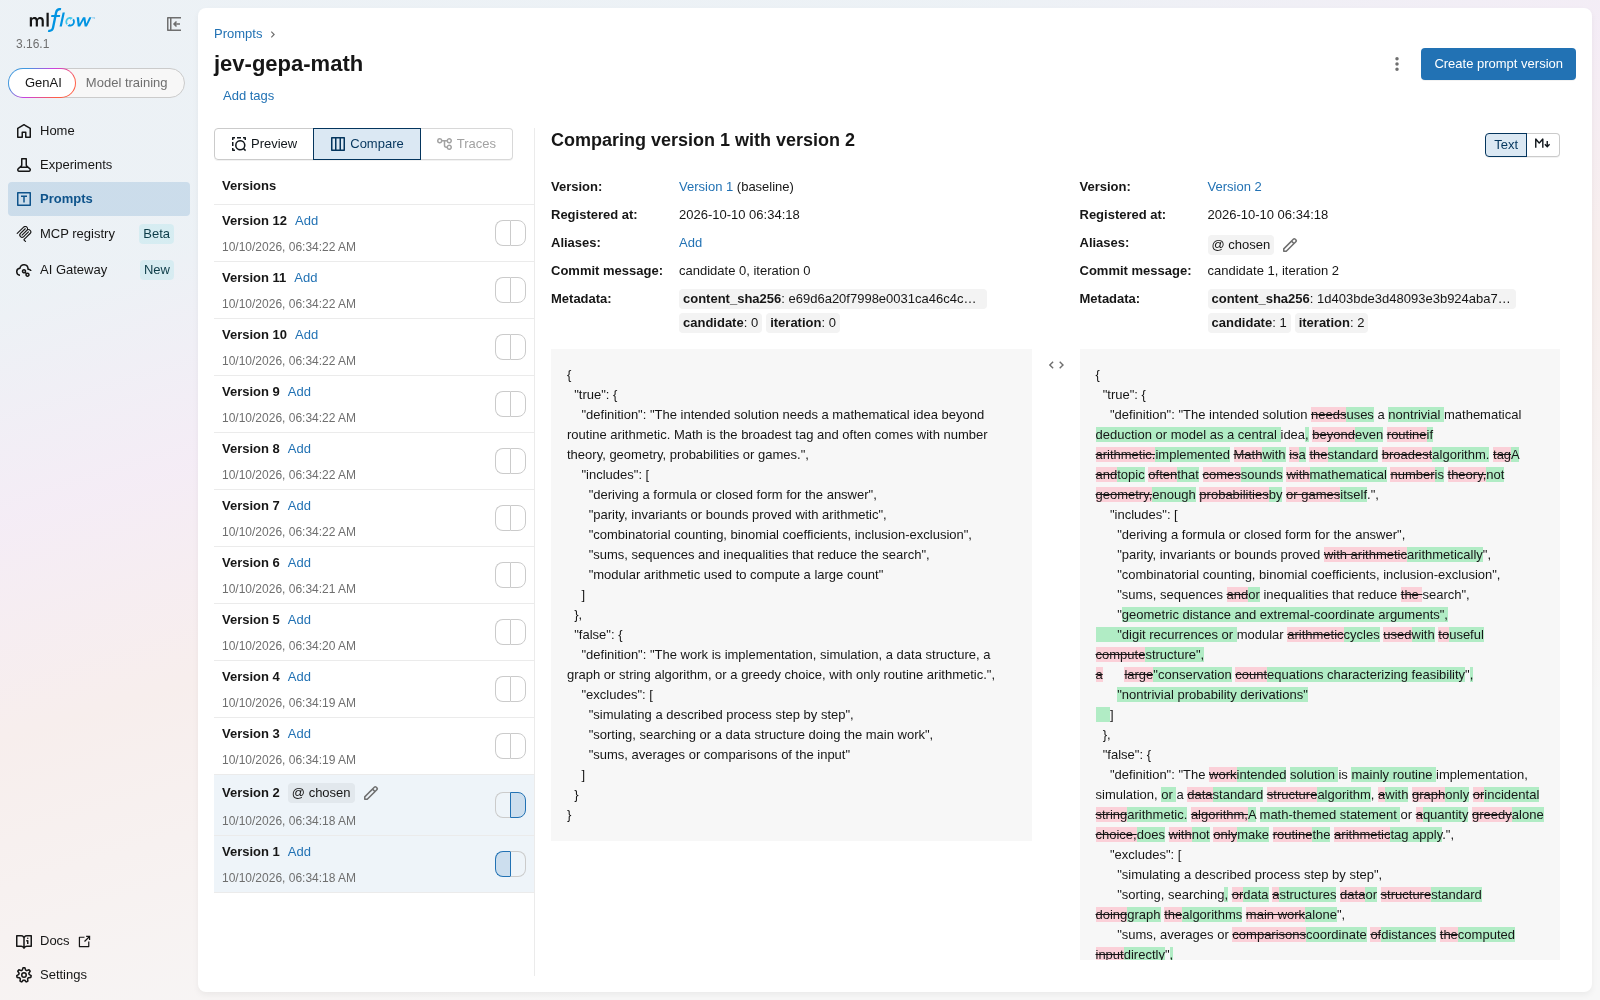

In [13]:
Image(filename=MLFLOW_SCREEN_GEPA_FOLDER / "03_gepa_prompt_compare.png", width=960)

## 4. The held-out fold

The honest dev comparison: fold 0, which the search never read. Each method's fold-0
predictions come from thresholds chosen on folds 1-4, and neither method saw a fold-0 label.
`jev-statement-code-gepa`'s scores on folds 1-4 are in sample for its words, so its fold-0
thresholds may fit fold 0 slightly worse: the bias is against it, not for it. Each method's F1
with its interval, and the paired difference with `jev-statement-code`, on the same group
bootstrap resamples; `jev-statement` is a second reference.

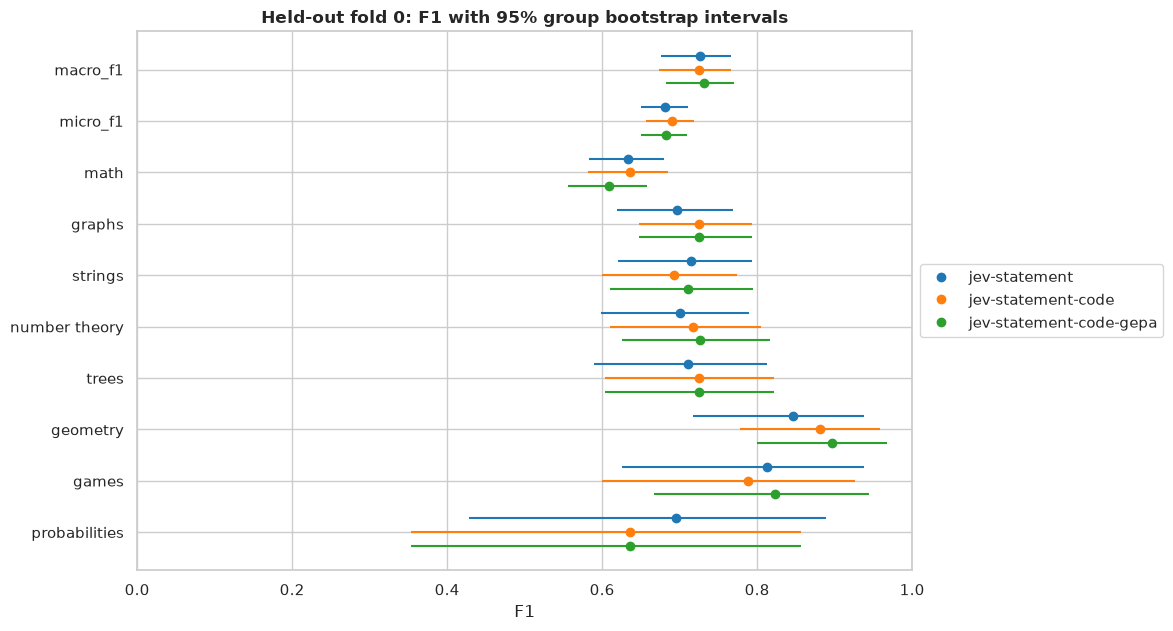

f1  f1_low  f1_high  delta  \
method                  metric                                         
jev-statement           macro_f1       0.726   0.676    0.766  0.001   
                        micro_f1       0.681   0.650    0.710 -0.009   
                        math           0.633   0.583    0.680 -0.003   
                        graphs         0.697   0.619    0.769 -0.028   
                        strings        0.715   0.620    0.793  0.022   
                        number theory  0.701   0.598    0.790 -0.016   
                        trees          0.711   0.589    0.812 -0.014   
                        geometry       0.846   0.717    0.938 -0.035   
                        games          0.812   0.625    0.938  0.025   
                        probabilities  0.696   0.429    0.889  0.059   
jev-statement-code      macro_f1       0.725   0.673    0.766  0.000   
                        micro_f1       0.690   0.657    0.719  0.000   
                        math           0.635   0.582    0.685  0.000   
                        graphs         0.724   0.648    0.793  0.000   
                        strings        0.693   0.600    0.774  0.000   
                        number theory  0.717   0.610    0.804  0.000   
                        trees          0.725   0.603    0.821  0.000   
                        geometry       0.881   0.778    0.959  0.000   
                        games          0.788   0.600    0.927  0.000   
                        probabilities  0.636   0.353    0.857  0.000   
jev-statement-code-gepa macro_f1       0.732   0.682    0.770  0.006   
                        micro_f1       0.682   0.650    0.710 -0.008   
                        math           0.609   0.555    0.657 -0.026   
                        graphs         0.724   0.648    0.793  0.000   
                        strings        0.711   0.611    0.795  0.018   
                        number theory  0.726   0.626    0.816  0.009   
                        trees          0.725   0.603    0.821  0.000   
                        geometry       0.897   0.800    0.968  0.015   
                        games          0.824   0.667    0.945  0.036   
                        probabilities  0.636   0.353    0.857  0.000   

                                       delta_low  delta_high  
method                  metric                                
jev-statement           macro_f1          -0.022       0.028  
                        micro_f1          -0.026       0.008  
                        math              -0.033       0.027  
                        graphs            -0.076       0.020  
                        strings           -0.008       0.056  
                        number theory     -0.087       0.057  
                        trees             -0.047       0.000  
                        geometry          -0.145       0.061  
                        games              0.000       0.086  
                        probabilities      0.000       0.215  
jev-statement-code      macro_f1           0.000       0.000  
                        micro_f1           0.000       0.000  
                        math               0.000       0.000  
                        graphs             0.000       0.000  
                        strings            0.000       0.000  
                        number theory      0.000       0.000  
                        trees              0.000       0.000  
                        geometry           0.000       0.000  
                        games              0.000       0.000  
                        probabilities      0.000       0.000  
jev-statement-code-gepa macro_f1          -0.006       0.022  
                        micro_f1          -0.023       0.008  
                        math              -0.056       0.003  
                        graphs             0.000       0.000  
                        strings           -0.035       0.070  
                        number theor

In [14]:
held_out_methods = {name: dev_by_method[name][held_out] for name in (*FROZEN_NAMES, GEPA)}
held_out_scores = method_scores(
    dev_labels[held_out], held_out_methods, groups[held_out], baseline=SEED
)
recorded = search_entries["held_out_macro_f1"]
assert np.isclose(held_out_scores.loc[(GEPA, "macro_f1"), "f1"], recorded, rtol=0, atol=1e-12)
ax = plot_method_f1(held_out_scores)
ax.figure.set_size_inches(10, 7)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("Held-out fold 0: F1 with 95% group bootstrap intervals")
plt.show()
held_out_scores.round(3)

The objective itself on the held-out fold: each tag's balanced Brier score (the mean of the
squared error on the tag's positives and on its negatives, halved each; lower is better), and
their mean over the eight tags.

In [15]:
brier = pd.DataFrame(
    {
        name: balanced_brier(dev_probabilities[name][held_out], dev_labels[held_out])
        for name in (*FROZEN_NAMES, GEPA)
    }
)
brier.loc["macro"] = [
    macro_balanced_brier(dev_probabilities[name][held_out], dev_labels[held_out])
    for name in brier.columns
]
brier.round(4)

,jev-statement,jev-statement-code,jev-statement-code-gepa
tag,,,
math,0.1770,0.1877,0.1761
graphs,0.0847,0.0705,0.0701
strings,0.0748,0.0747,0.0749
number theory,0.0967,0.0856,0.0844
trees,0.1096,0.0956,0.0971
geometry,0.0504,0.0180,0.0183
games,0.0393,0.0411,0.0405
probabilities,0.2187,0.2078,0.1834
macro,0.1064,0.0976,0.0931


**On the held-out fold, the searched words show no detectable difference in macro F1 from the frozen words.**

- `jev-statement-code-gepa` reaches a macro F1 of 0.732 [0.682, 0.770] and a micro F1 of 0.682 [0.650, 0.710]; frozen `jev-statement-code` reaches 0.725 [0.673, 0.766] and 0.690 [0.657, 0.719], and `jev-statement` 0.726 [0.676, 0.766] and 0.681 [0.650, 0.710].
- Paired, `jev-statement-code-gepa` minus `jev-statement-code` is +0.006 [-0.006, 0.022] in macro F1 and -0.008 [-0.023, 0.008] in micro F1: both intervals contain 0.
- No tag's paired interval excludes 0. Math, one of the two rewritten tags, falls from 0.635 to 0.609, -0.026 [-0.056, 0.003]; probabilities, the other, stays at 0.636, with the same fold-0 predictions. Geometry (+0.015 [0.000, 0.055]) and games (+0.036 [0.000, 0.127]) each gain one problem (section 6), and graphs and trees do not move.
- Strings (+0.018 [-0.035, 0.070]) and number theory (+0.009 [-0.038, 0.059]) moved although their words did not change: each answer is a new request to Jev, and the thresholds were chosen again on the new scores.
- The objective did improve on the held-out fold: the macro balanced Brier score falls from 0.0976 to 0.0931 (`jev-statement`: 0.1064), on the two rewritten tags, probabilities (0.2078 to 0.1834) and math (0.1877 to 0.1761); the six other tags move by at most 0.0015 (trees, 0.0956 to 0.0971).
- Fold 0 holds few positives of the rare tags, 15 for probabilities, 16 for games and 27 for geometry (section 1), so their intervals are wide.

The searched words lower the score they were searched on, on a fold the search never read, but the better probabilities do not make better tags: the paired macro F1 difference on fold 0 is +0.006, and its interval contains 0.

## 5. All of dev, in sample

On every dev problem, labelled in sample: the new words were chosen on folds 1-4. First each
tag's mean probability before (`jev-statement-code`) and after (`jev-statement-code-gepa`)
against its base rate, with each method's final thresholds, chosen on every dev problem: did the
search lower Jev's probabilities toward the base rates, which the frozen thresholds (all but
math's above 0.5) already corrected? Then a closer look at probabilities, whose threshold moved
most. Then each method's macro F1 per fold, and the paired difference over all of dev, which is
not an honest estimate.

In [16]:
shift = probability_shift(dev_probabilities[SEED], dev_probabilities[GEPA], dev_labels)
thresholds = pd.DataFrame(
    {name: load_method(model_dir(name)).thresholds.thresholds_ for name in (SEED, GEPA)},
    index=TAGS,
)
shift.join(thresholds.add_prefix("threshold ")).round(3)

,base_rate,mean_before,mean_after,threshold jev-statement-code,threshold jev-statement-code-gepa
tag,,,,,
math,0.283,0.316,0.369,0.335,0.395
graphs,0.109,0.199,0.199,0.745,0.785
strings,0.085,0.175,0.175,0.895,0.915
number theory,0.070,0.167,0.167,0.695,0.765
trees,0.065,0.093,0.093,0.645,0.665
geometry,0.033,0.058,0.058,0.615,0.600
games,0.021,0.057,0.057,0.820,0.785
probabilities,0.019,0.033,0.034,0.870,0.125


**The threshold of probabilities.** Each method's final threshold for `probabilities` was
chosen on every dev problem, as the one with the highest dev F1. For each method's dev scores:
how many of the tag's positives and negatives reach each of the two thresholds (a score at or
above it), the dev F1 there, then the quantiles of the positives' probabilities.

In [17]:
positive = dev_labels["probabilities"] == 1
reached = pd.DataFrame(
    [
        {
            "method": name,
            "threshold_of": owner,
            "threshold": cut,
            "positives": int((dev_probabilities[name].loc[positive, "probabilities"] >= cut).sum()),
            "negatives": int(
                (dev_probabilities[name].loc[~positive, "probabilities"] >= cut).sum()
            ),
        }
        for name in (SEED, GEPA)
        for owner, cut in thresholds.loc["probabilities"].items()
    ]
).set_index(["method", "threshold_of"])
predicted = reached["positives"] + reached["negatives"]
reached["dev_f1"] = 2 * reached["positives"] / (predicted + positive.sum())
print(f"probabilities on dev: {int(positive.sum())} positives, {int((~positive).sum())} negatives")
display(reached.round(3))
quantiles = [0.1, 0.25, 0.5, 0.75]
pd.DataFrame(
    {
        name: dev_probabilities[name].loc[positive, "probabilities"].quantile(quantiles)
        for name in (SEED, GEPA)
    }
).rename_axis("quantile of the positives").round(3)

probabilities on dev: 74 positives, 3914 negatives


threshold  positives  \
method                  threshold_of                                    
jev-statement-code      jev-statement-code           0.870         50   
                        jev-statement-code-gepa      0.125         52   
jev-statement-code-gepa jev-statement-code           0.870         48   
                        jev-statement-code-gepa      0.125         65   

                                                 negatives  dev_f1  
method                  threshold_of                                
jev-statement-code      jev-statement-code               7   0.763  
                        jev-statement-code-gepa         27   0.680  
jev-statement-code-gepa jev-statement-code               6   0.750  
                        jev-statement-code-gepa         32   0.760

,jev-statement-code,jev-statement-code-gepa
quantile of the positives,,
0.10,0.053,0.063
0.25,0.103,0.332
0.50,0.970,0.950
0.75,0.980,0.970


In [18]:
fold_roles = {SEARCH_HELD_OUT_FOLD: "held-out", SEARCH_SELECTION_FOLD: "selection"}
by_fold = pd.DataFrame(
    {
        name: {
            f"fold {fold} ({fold_roles.get(fold, 'learning')})": evaluate(
                dev_labels[(folds == fold).to_numpy()],
                dev_by_method[name][(folds == fold).to_numpy()],
            ).macro_f1
            for fold in sorted(folds.unique())
        }
        for name in (SEED, GEPA)
    }
)
by_fold["difference"] = by_fold[GEPA] - by_fold[SEED]
display(by_fold.round(3))
all_dev = method_scores(
    dev_labels, {name: dev_by_method[name] for name in (SEED, GEPA)}, groups, baseline=SEED
)
all_dev.loc[GEPA].round(3)

,jev-statement-code,jev-statement-code-gepa,difference
fold 0 (held-out),0.725,0.732,0.006
fold 1 (learning),0.724,0.726,0.003
fold 2 (learning),0.699,0.703,0.004
fold 3 (learning),0.736,0.734,-0.002
fold 4 (selection),0.754,0.753,-0.001


,f1,f1_low,f1_high,delta,delta_low,delta_high
metric,,,,,,
macro_f1,0.730,0.712,0.746,0.001,-0.008,0.010
micro_f1,0.676,0.662,0.689,-0.008,-0.014,-0.001
math,0.619,0.596,0.641,-0.019,-0.032,-0.007
graphs,0.711,0.679,0.744,0.008,0.001,0.015
strings,0.660,0.620,0.701,-0.000,-0.013,0.012
number theory,0.680,0.635,0.725,-0.006,-0.020,0.008
trees,0.805,0.762,0.841,0.004,-0.006,0.015
geometry,0.772,0.712,0.822,0.011,0.003,0.023
games,0.874,0.817,0.923,0.044,0.004,0.090


**The new words did not pull Jev's probabilities toward the base rates: math's rose further above its base rate, and the thresholds moved instead.**

- Math: a mean probability of 0.316 before and 0.369 after, against a base rate of 0.283; its final threshold rose from 0.335 to 0.395.
- Probabilities: 0.033 before and 0.034 after, against a base rate of 0.019; its final threshold fell from 0.870 to 0.125, the largest move of any threshold, and is now the only one besides math's below 0.5.
- The threshold of probabilities fell because the new words lifted its low-scoring positives: the 25th percentile of the 74 dev positives' probabilities rose from 0.103 to 0.332, while their median stayed near the top (0.970 and 0.950). With the seed's scores, lowering the threshold from 0.870 to 0.125 reaches 2 more positives and 20 more negatives (dev F1 0.763 to 0.680); with the new scores, 17 more positives and 26 more negatives (0.750 to 0.760). For the new scores, two thresholds far apart give almost the same dev F1, and the low one won by 0.010.
- The six other tags keep their mean probabilities to 3 decimals, and their thresholds move by up to 0.070 (number theory, 0.695 to 0.765): each answer is a new request, and the thresholds are chosen again.
- Per fold, the macro F1 difference is +0.006 on the held-out fold 0, +0.003, +0.004 and -0.002 on the learning folds 1 to 3, and -0.001 on the selection fold 4: the folds the search read gain no more than the fold it never read.
- Over all of dev, labelled in sample, `jev-statement-code-gepa` reaches a macro F1 of 0.730 [0.712, 0.746]; its paired difference with `jev-statement-code` is +0.001 [-0.008, 0.010] in macro F1 and -0.008 [-0.014, -0.001] in micro F1. Per tag, math loses -0.019 [-0.032, -0.007], and graphs (+0.008 [0.001, 0.015]), geometry (+0.011 [0.003, 0.023]) and games (+0.044 [0.004, 0.090]) gain; probabilities moves by -0.034 [-0.093, 0.025].

Even in sample, on the folds whose answers chose the words, the macro F1 does not move and the micro F1 and math lose: the search lowered the balanced Brier score, and F1 through cross-fitted thresholds does not reward it.

## 6. Errors on the held-out fold

The fold-0 problems whose 0/1 prediction on a tag differs between the two methods: per tag, how
many the new words made right and how many they made wrong, then the problems of the tag with the
most changes, with their tags and the start of their statement.

In [19]:
flips = {
    tag: flipped(
        dev_by_method[SEED][held_out], dev_by_method[GEPA][held_out], dev_labels[held_out], tag
    )
    for tag in TAGS
}
flip_counts = pd.DataFrame(
    {
        "wrong_to_right": {tag: int(table["now_right"].sum()) for tag, table in flips.items()},
        "right_to_wrong": {tag: int((~table["now_right"]).sum()) for tag, table in flips.items()},
    }
)
flip_counts["net"] = flip_counts["wrong_to_right"] - flip_counts["right_to_wrong"]
display(flip_counts)
most = (flip_counts["wrong_to_right"] + flip_counts["right_to_wrong"]).idxmax()
print(f"{most}: the problems of the held-out fold whose prediction changed")
tags_and_statement = dev["tags"].str.join(", ").to_frame().join(dev["statement"].str.slice(0, 160))
flips[most].join(tags_and_statement).head(8)

,wrong_to_right,right_to_wrong,net
math,22,43,-21
graphs,0,0,0
strings,13,5,8
number theory,3,4,-1
trees,0,0,0
geometry,1,0,1
games,1,0,1
probabilities,0,0,0


math: the problems of the held-out fold whose prediction changed


,gold,before,after,now_right,tags,statement
sample_id,,,,,,
290,0,0,1,False,"implementation, greedy","Wilbur the pig is tinkering with arrays again. He has the array a1, a2, ..., an initially consisting of n ..."
291,1,1,0,False,"brute force, math","You are given three integers $$$a \le b \le c$$$. In one move, you can add $$$+1$$$ or $$$-1$$$ to any of ..."
473,0,1,0,True,"data structures, two pointers, number theory, brute force","Ehab loves number theory, but for some reason he hates the number $$$x$$$. Given an array $$$a$$$, find th..."
486,1,1,0,False,"implementation, math",Suppose there is a $$$h \times w$$$ grid consisting of empty or full cells. Let's make some definitions: ...
617,0,0,1,False,"constructive algorithms, implementation, dfs and similar, trees",Note that this is the second problem of the two similar problems. You can hack this problem if you solve i...
668,1,1,0,False,"dp, number theory, math, implementation, data structures, binary search, brute force","Recently, the bear started studying data structures and faced the following problem. You are given a seque..."
764,0,0,1,False,"implementation, greedy","Once again, Boris needs the help of Anton in creating a task. This time Anton needs to solve the following..."
798,0,0,1,False,"implementation, bitmasks, brute force",Magnus decided to play a classic chess game. Though what he saw in his locker shocked him! His favourite c...


**On the held-out fold, the new math words made more predictions wrong than right.**

- Math: 22 fold-0 predictions made right and 43 made wrong, a net of -21. Strings: 13 made right and 5 made wrong, a net of +8; number theory: 3 and 4, a net of -1; geometry and games: one made right each. On graphs, trees and probabilities no prediction changed.
- Math has the most changes. Of the eight problems shown, four now get math without having it: problems 290 and 764 (implementation, greedy), 798 (implementation, bitmasks, brute force) and 617 (constructive algorithms, implementation, dfs and similar, trees). Three lose the math they have: problems 291 (brute force, math), 486 (implementation, math) and 668 (dp, number theory, math, implementation, data structures, binary search, brute force). Only problem 473 (data structures, two pointers, number theory, brute force) loses a math it does not have.
- Every one of the eight is tagged implementation or brute force: among these eight, the line the new words draw between a core mathematical idea and routine implementation is where they err, in both directions.

The rewrite moved math's errors without reducing them: among the problems shown, it adds math to implementation problems that lack it and drops it from implementation and brute-force problems that Codeforces tags math.

## 7. The test set, reported once

Each method's frozen test predictions, scored once, side by side: the new method's test answers
were asked after its dev answers were committed, its thresholds were chosen on every dev
problem, and nothing is chosen from these numbers (ADR 0001). `jev-statement-code`, `tfidf` and
`label_prior` are references.

In [20]:
reported = [GEPA, SEED, TFIDF, PRIOR]
test_results = {
    name: evaluate(
        test_labels,
        test_by_method[name],
        release_years=release_years(test),
        groups=test["group"],
    )
    for name in reported
}
display(pd.DataFrame({name: result.overall_f1() for name, result in test_results.items()}).round(3))
test_summary = pd.DataFrame(
    {name: result.summary.loc[ALL_PROBLEMS] for name, result in test_results.items()}
).T
interval_columns = ["macro_f1", "macro_f1_low", "macro_f1_high"]
test_summary[[*interval_columns, "micro_f1", "micro_f1_low", "micro_f1_high"]].round(3)

,jev-statement-code-gepa,jev-statement-code,tfidf,label_prior
metric,,,,
macro_f1,0.727,0.751,0.689,0.149
micro_f1,0.677,0.694,0.633,0.158
math,0.636,0.659,0.619,0.441
graphs,0.703,0.713,0.557,0.196
strings,0.660,0.663,0.660,0.158
number theory,0.663,0.659,0.518,0.135
trees,0.756,0.767,0.772,0.119
geometry,0.781,0.781,0.706,0.064
games,0.905,0.927,0.878,0.041


,macro_f1,macro_f1_low,macro_f1_high,micro_f1,micro_f1_low,micro_f1_high
jev-statement-code-gepa,0.727,0.692,0.758,0.677,0.650,0.703
jev-statement-code,0.751,0.720,0.777,0.694,0.668,0.719
tfidf,0.689,0.649,0.721,0.633,0.604,0.661
label_prior,0.149,0.139,0.158,0.158,0.148,0.168


The two Jev methods paired, on the same group bootstrap resamples of the test set:
`jev-statement-code-gepa` minus `jev-statement-code` on every metric, and the share of the macro
F1 difference that `probabilities` carries (its difference divided by the eight tags, over the
macro F1 difference). Then each method's counts on `probabilities`, at its own threshold. This
reports a difference; nothing is chosen from it (ADR 0001).

In [21]:
paired_test = method_scores(
    test_labels,
    {name: test_by_method[name] for name in (SEED, GEPA)},
    test["group"],
    baseline=SEED,
)
display(paired_test.loc[GEPA].round(3))
macro_delta = paired_test.loc[(GEPA, "macro_f1"), "delta"]
probabilities_delta = paired_test.loc[(GEPA, "probabilities"), "delta"]
print(
    f"probabilities' share of the macro F1 difference: "
    f"{probabilities_delta / len(TAGS) / macro_delta:.2f}"
)
counts = ["support", "tp", "fp", "fn", "f1"]
pd.concat(
    {
        name: test_results[name].per_tag.loc[ALL_PROBLEMS].loc[["probabilities"], counts]
        for name in (GEPA, SEED)
    }
).round(3)

,f1,f1_low,f1_high,delta,delta_low,delta_high
metric,,,,,,
macro_f1,0.727,0.692,0.758,-0.025,-0.041,-0.010
micro_f1,0.677,0.650,0.703,-0.017,-0.032,-0.003
math,0.636,0.593,0.676,-0.024,-0.053,0.004
graphs,0.703,0.635,0.766,-0.010,-0.032,0.009
strings,0.660,0.577,0.734,-0.004,-0.041,0.030
number theory,0.663,0.571,0.745,0.003,-0.043,0.045
trees,0.756,0.661,0.835,-0.010,-0.036,0.000
geometry,0.781,0.655,0.886,0.000,0.000,0.000
games,0.905,0.800,0.980,-0.022,-0.079,0.000


probabilities' share of the macro F1 difference: 0.66


,,support,tp,fp,fn,f1
,tag,,,,,
jev-statement-code-gepa,probabilities,18,16,11,2,0.711
jev-statement-code,probabilities,18,16,4,2,0.842


**On the test set, reported once, `jev-statement-code-gepa` scores below the frozen `jev-statement-code`, and the paired difference excludes 0.**

- `jev-statement-code-gepa` reaches a macro F1 of 0.727 [0.692, 0.758] and a micro F1 of 0.677; `jev-statement-code` 0.751 [0.720, 0.777] and 0.694; `tfidf` 0.689 [0.649, 0.721] and 0.633; `label_prior` 0.149 [0.139, 0.158] and 0.158.
- Paired on the same resamples, `jev-statement-code-gepa` minus `jev-statement-code` is -0.025 [-0.041, -0.010] in macro F1 and -0.017 [-0.032, -0.003] in micro F1: both intervals exclude 0. Per tag, only probabilities' interval excludes 0, at -0.131 [-0.236, -0.043]; math is -0.024 [-0.053, 0.004] and games -0.022 [-0.079, 0.000], number theory is the one tag ahead (+0.003 [-0.043, 0.045]), and geometry is equal (0.781).
- Probabilities carries 0.66 of the macro F1 difference, about two thirds. Both methods find 16 of its 18 test positives, but at its threshold of 0.125 the new method also tags 11 negatives, against 4 for the seed at 0.870: an F1 of 0.711 against 0.842. The test loss runs mostly through probabilities, whose threshold fell from 0.870 to 0.125 on a nearly flat dev F1 curve (section 5).
- `jev-statement-code-gepa`'s macro F1 on the held-out fold, 0.732, lies inside its test interval [0.692, 0.758].

These numbers are a reference: both methods were fixed on dev, and the paired difference reports what the searched words cost on test without choosing anything (ADR 0001).

## 8. Latency and cost per request

`tracking latency` timed one prediction per problem on 50 dev problems, each a live request to
Jev, against the 10-second budget of a single prediction (`LATENCY_BUDGET_S`); then each
method's mean cost per request, by part, from its answers files.

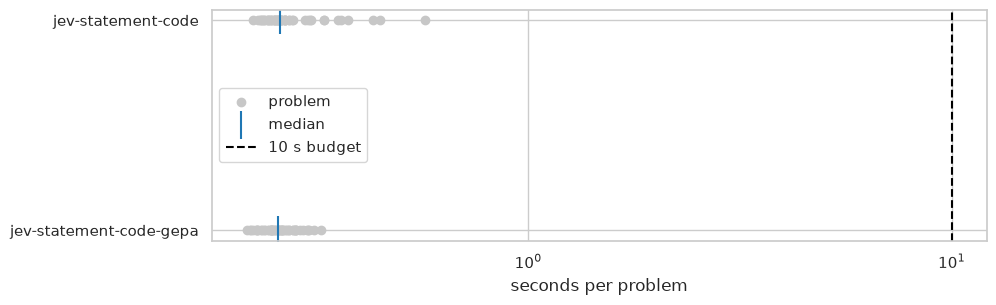

,median_s,p95_s,max_s,under_budget
jev-statement-code,0.260,0.405,0.570,True
jev-statement-code-gepa,0.257,0.303,0.324,True


,jev-statement-code,jev-statement-code-gepa
part,,
dev,0.000134,0.000139
test,0.000133,0.000137


In [22]:
timed = {name: load_latency(method_dir(name)) for name in (SEED, GEPA)}
ax = plot_latency({name: timing.seconds for name, timing in timed.items()})
ax.figure.set_size_inches(10, 3)
plt.show()
latency_table = pd.DataFrame(
    {name: latency_summary(timing.seconds) for name, timing in timed.items()}
).T
latency_table["under_budget"] = latency_table["max_s"] < LATENCY_BUDGET_S
display(latency_table.round(3))
pd.concat(
    {
        name: frame.groupby(level="part", sort=False)["total_cost_usd"].mean()
        for name, frame in calls.items()
    },
    axis="columns",
).round(6)

**The longer words leave a prediction's latency at a quarter of a second, and add little to its cost.**

- `jev-statement-code-gepa`: median 0.257 s, maximum 0.324 s; `jev-statement-code`: median 0.260 s, maximum 0.570 s. Both are under the 10-second budget.
- The mean cost per request is $0.000139 against $0.000134 on dev, and $0.000137 against $0.000133 on test.

One live prediction stays far under the budget; the two methods were timed in separate runs of `tracking latency`, so the gap between their maxima reflects the network as much as the words.

## 9. Takeaways and next steps

**Results**
- **Section 2, the words.** Only math (818 to 1,190 characters) and probabilities (639 to 857) changed; a request reads 112.0 more input tokens and costs $0.000139 instead of $0.000134 on dev.
- **Section 3, the search.** 200 iterations, 70 children accepted, 104 proposals refused as too long, all 71 candidates through the dataset-text check; candidate 69 scores 0.9135 on the selection fold against the seed's 0.9091, for $9.9477 under the $15 cap.
- **Section 4, the held-out fold.** A macro F1 of 0.732 [0.682, 0.770] against 0.725 [0.673, 0.766], a paired +0.006 [-0.006, 0.022]; math -0.026 [-0.056, 0.003]; the macro balanced Brier score falls from 0.0976 to 0.0931.
- **Section 5, all of dev, in sample.** +0.001 [-0.008, 0.010] in macro F1; math's mean probability rises from 0.316 to 0.369 against a base rate of 0.283, and the threshold of probabilities falls from 0.870 to 0.125, where the new scores' dev F1 is 0.760 against 0.750 at 0.870.
- **Section 6, errors.** On fold 0, the new math words make 22 predictions right and 43 wrong.
- **Section 7, test, reported once.** 0.727 [0.692, 0.758] against 0.751 [0.720, 0.777] for `jev-statement-code`, a paired -0.025 [-0.041, -0.010]; probabilities, 0.711 against 0.842 (-0.131 [-0.236, -0.043]), carries 0.66 of the macro F1 difference.
- **Section 8, latency.** A median of 0.257 s and a maximum of 0.324 s, against 0.260 s and 0.570 s.

Searching Jev's words lowered the balanced Brier score it was searched on, on the selection fold and on the held-out fold, but showed no detectable difference in macro F1 on the held-out fold, where the paired difference is +0.006 [-0.006, 0.022]. On the test set, a reference, the paired difference is -0.025 [-0.041, -0.010]: the test loss runs mostly through probabilities (0.66 of the macro loss, about two thirds), whose threshold fell from 0.870 to 0.125 on a nearly flat dev F1 curve. Under a protocol fixed before the search, that is a finding: on this objective and this budget, better probabilities did not make better tags. `jev-statement-code-gepa` is `dev_in_sample`, a reference that is never the command line's default (ADR 0004, ADR 0008), which stays `jev-statement-code`.

**Next steps**
- **A nested search.** Searching inside each of the five dev folds, each time with one fold held
  out, would give every dev problem an honest score and make a searched method eligible for the
  command line's choice (ADR 0004), for about five times the search's cost.
- **The statement-only method.** A search over the words of `jev-statement`, which reads about
  13% fewer input tokens, would tell whether better words recover what the solution adds.
- **The question template.** The search kept `QUESTION` fixed: rewriting it would be a tenth
  piece, and a new method under a new name (ADR 0003).
- **More positives for the rare tags.** The held-out fold holds few `probabilities` and `games`
  positives (section 1); a nested search would read all five folds' positives instead.